In [1]:
from helper_functions.get_data_dictionary_target_X_y_imports import *

Loaded: 
      data: the entire dataset.
      dictionary: the data dictionary.
      X: the features columns with 'inhospital_mortality', 'studyid_adm', 'lengthadm' dropped.
      y: the target column.


In [25]:
special_features = dictionary[
    dictionary.Feature.str.startswith('symptoms_adm') & ~dictionary.Feature.str.endswith('_17')].Feature.tolist()
df = data[special_features + [target]]

In [26]:
for col in special_features:
    df[col] = np.where(df[col]=='Checked', 1, 0)
    print(df[col].unique())

[0 1]
[0 1]
[0 1]
[0 1]
[0 1]
[1 0]
[0 1]
[0 1]
[0 1]
[0 1]
[0 1]
[0 1]
[0 1]
[1 0]
[0 1]
[0 1]
[0]


In [27]:
special_features


[
    'symptoms_adm___1',
    'symptoms_adm___2',
    'symptoms_adm___3',
    'symptoms_adm___4',
    'symptoms_adm___5',
    'symptoms_adm___6',
    'symptoms_adm___7',
    'symptoms_adm___8',
    'symptoms_adm___9',
    'symptoms_adm___10',
    'symptoms_adm___11',
    'symptoms_adm___12',
    'symptoms_adm___13',
    'symptoms_adm___14',
    'symptoms_adm___15',
    'symptoms_adm___16',
    'symptoms_adm___18'
]

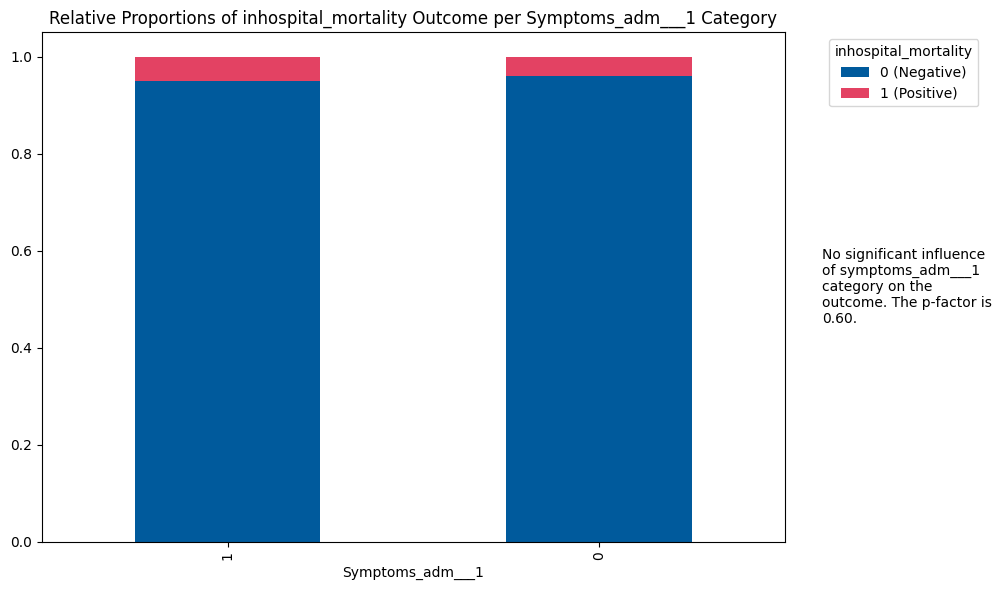

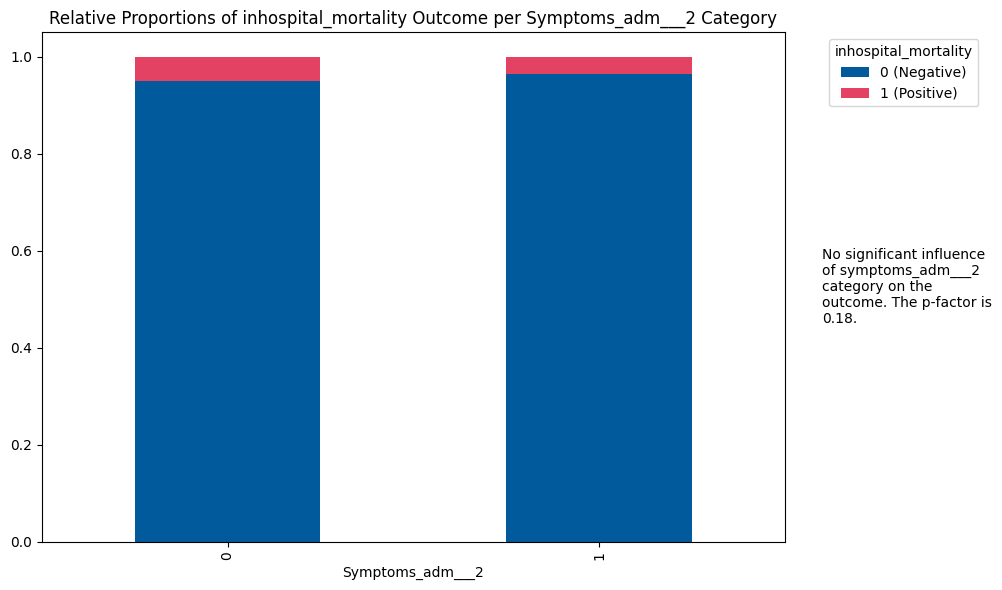

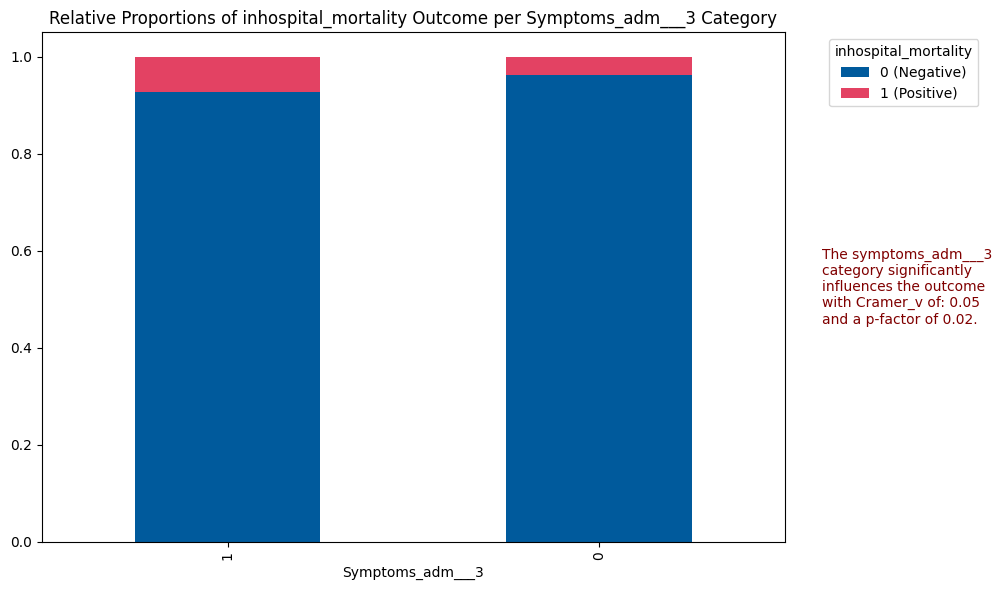

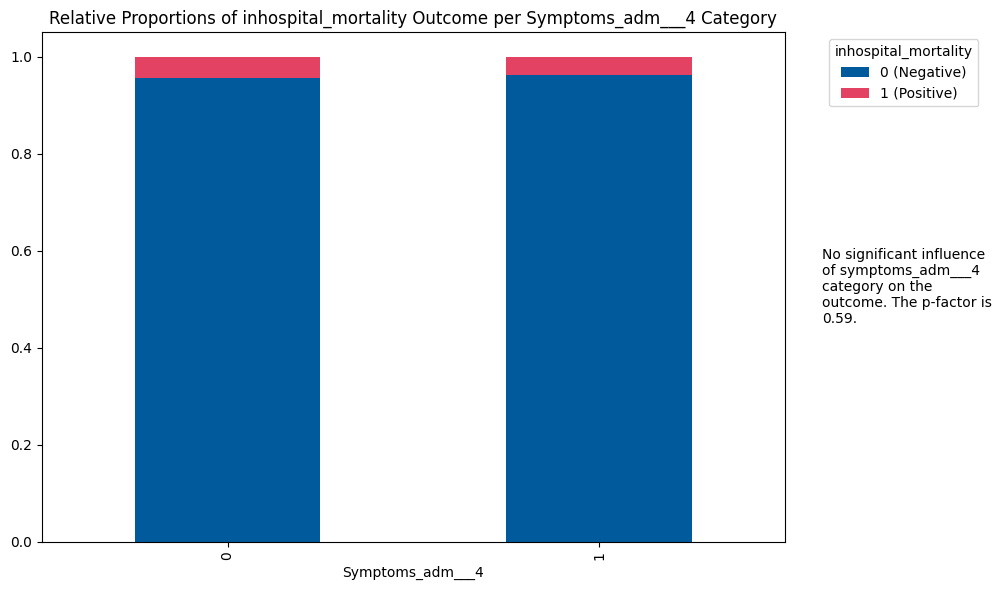

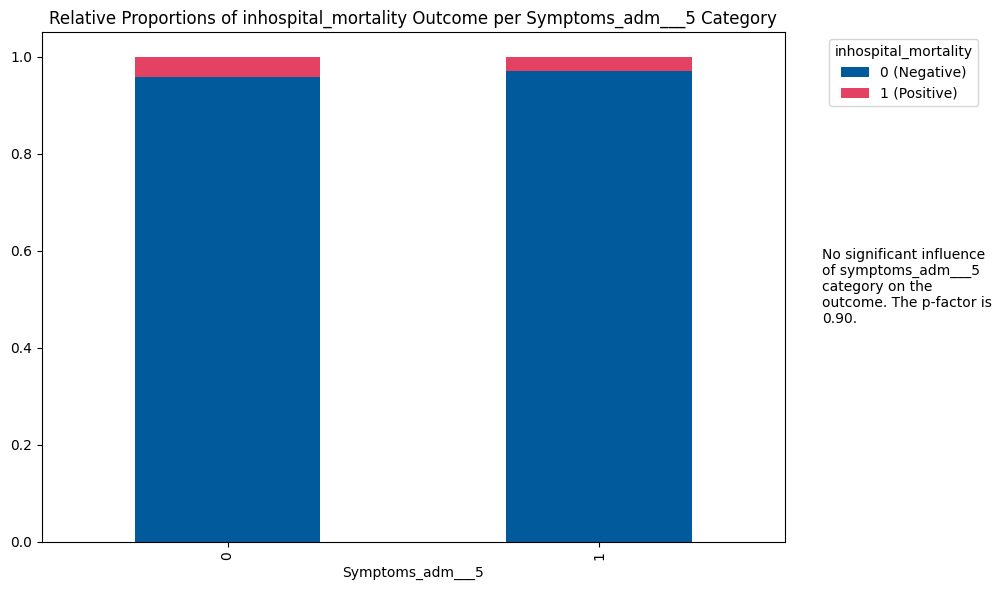

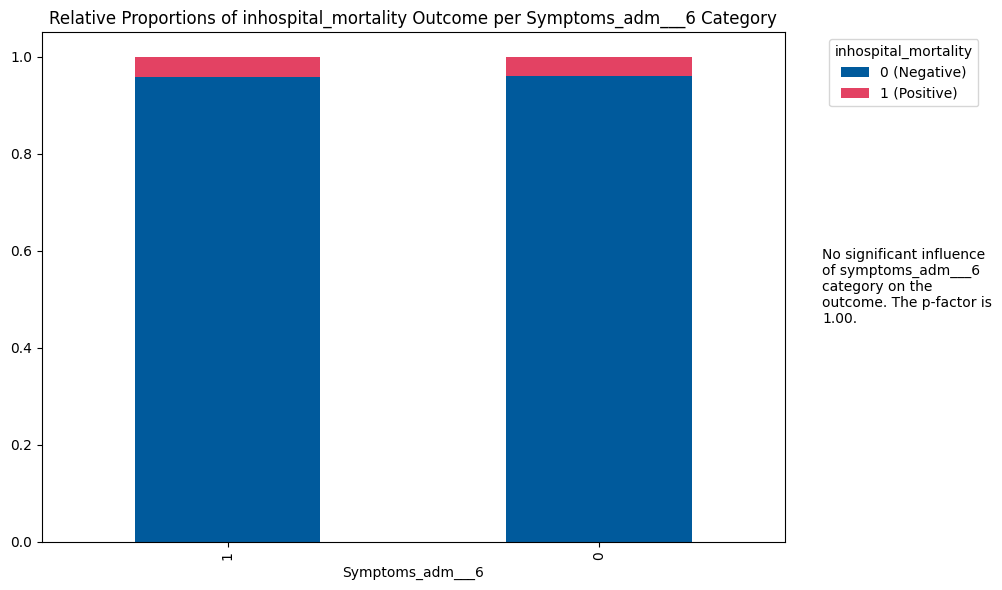

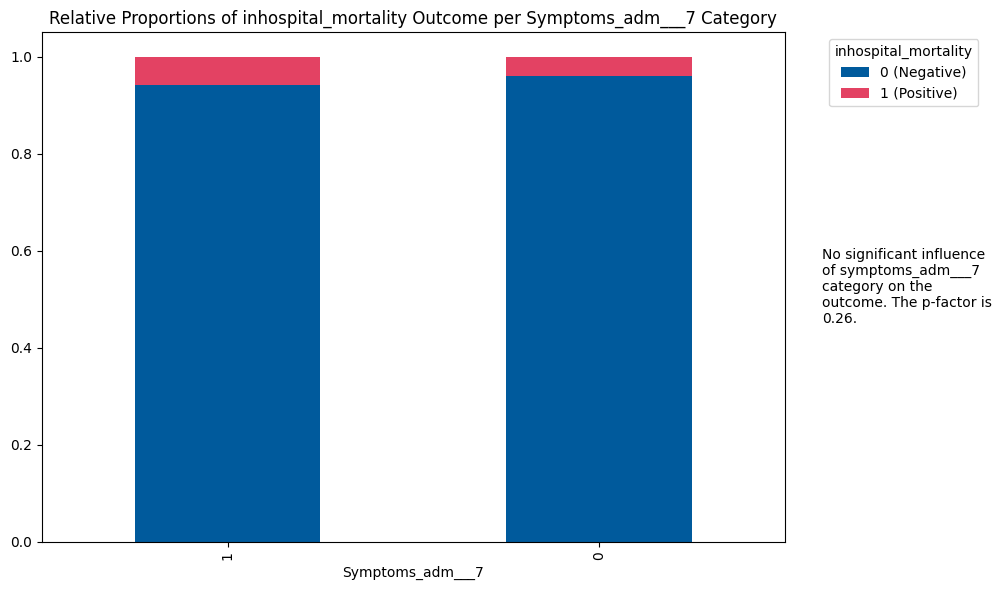

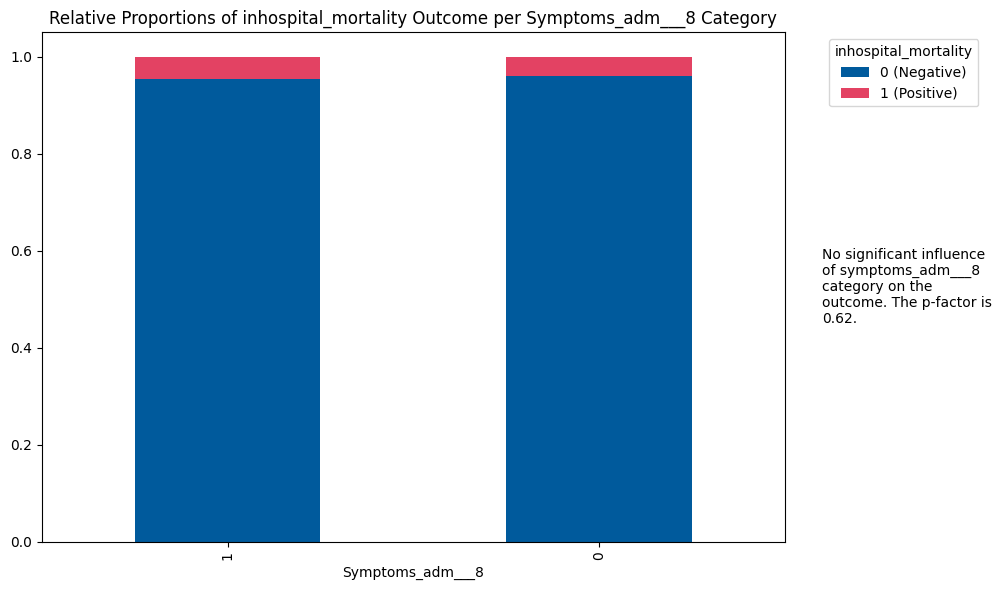

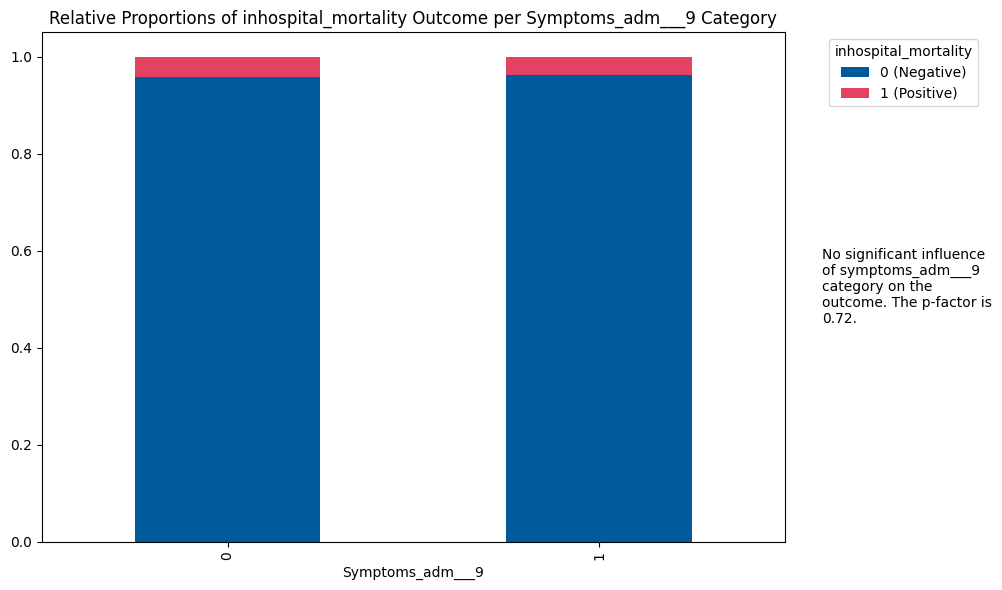

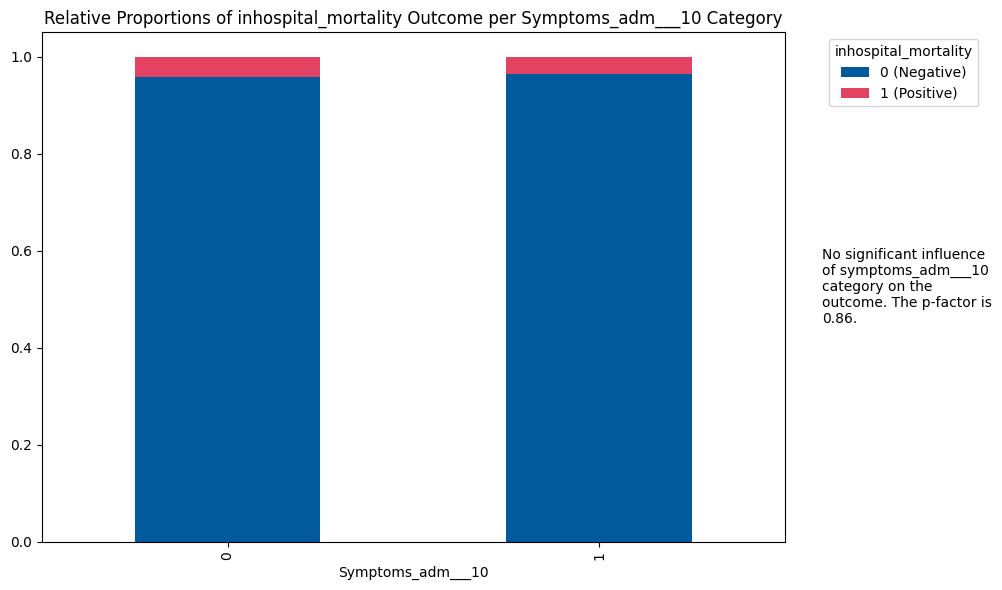

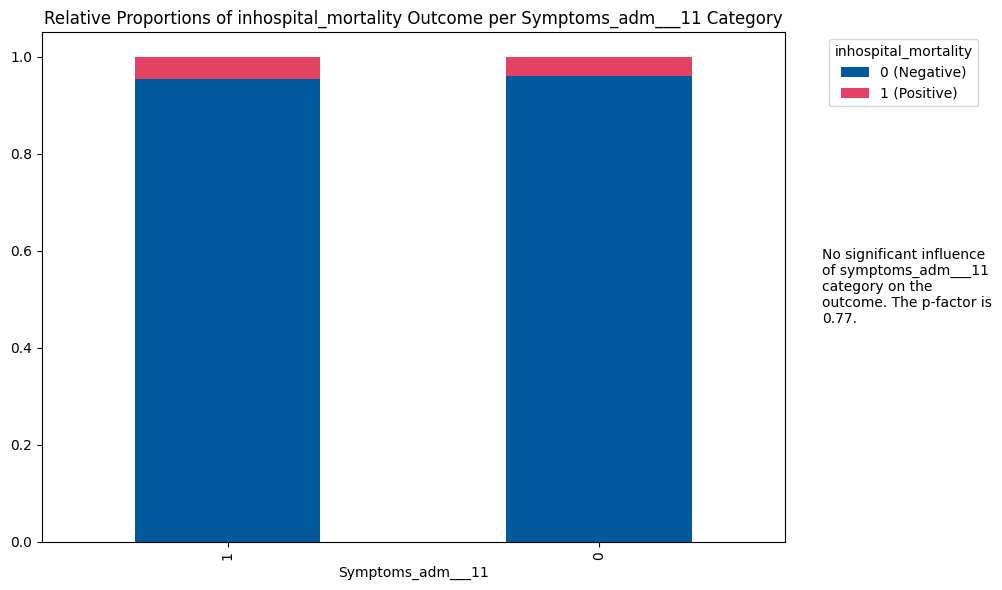

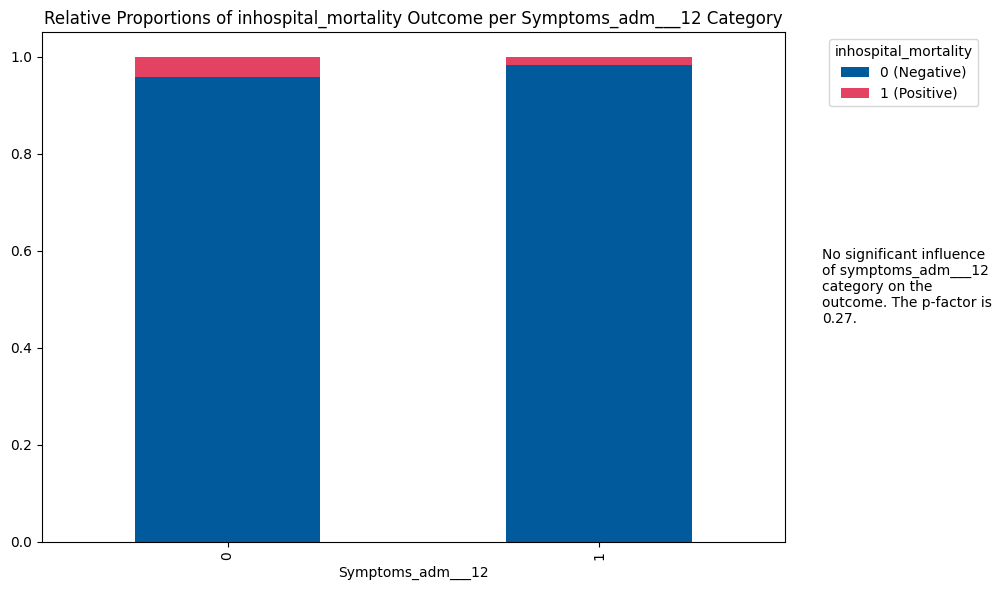

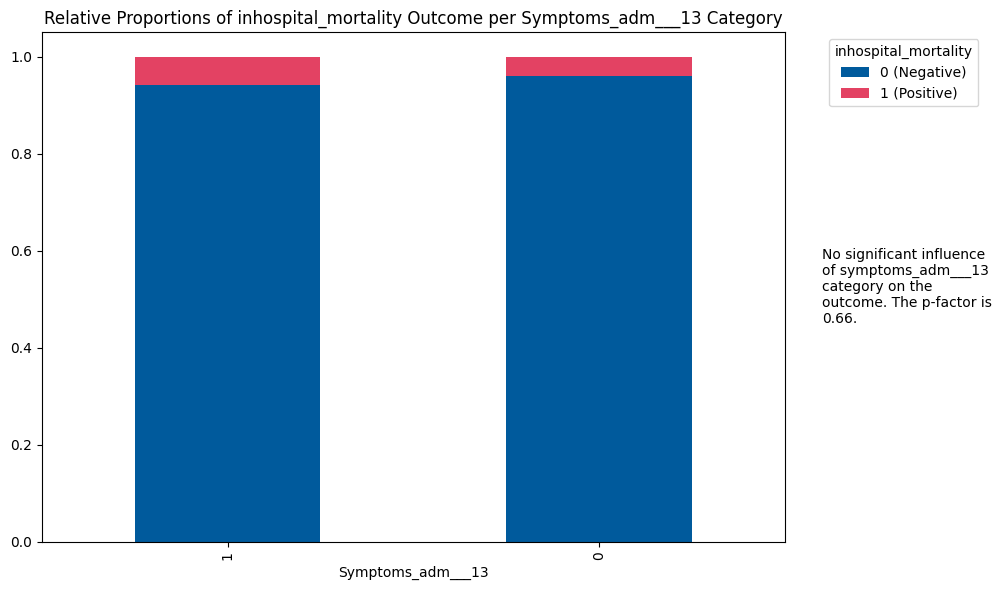

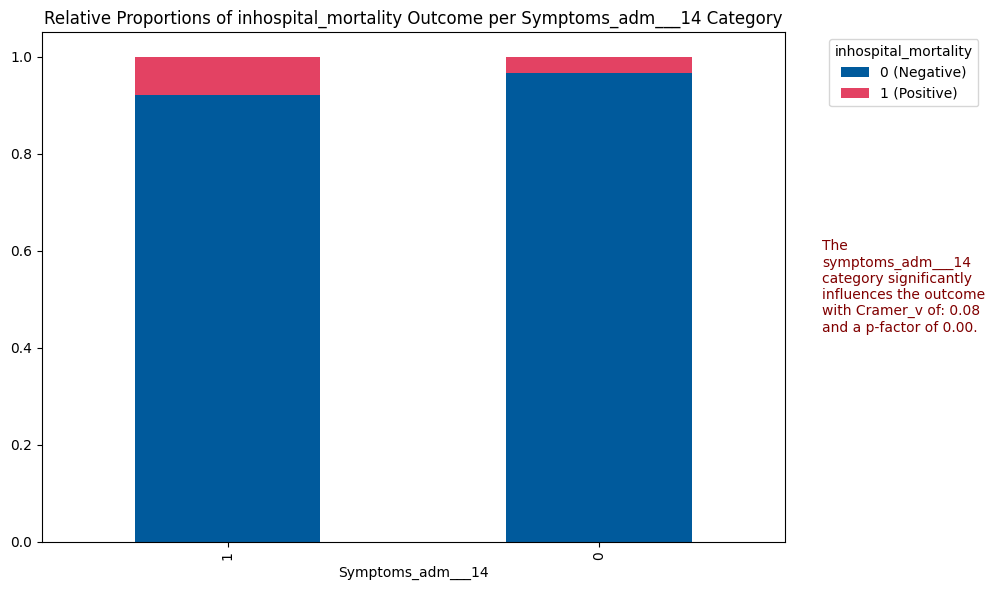

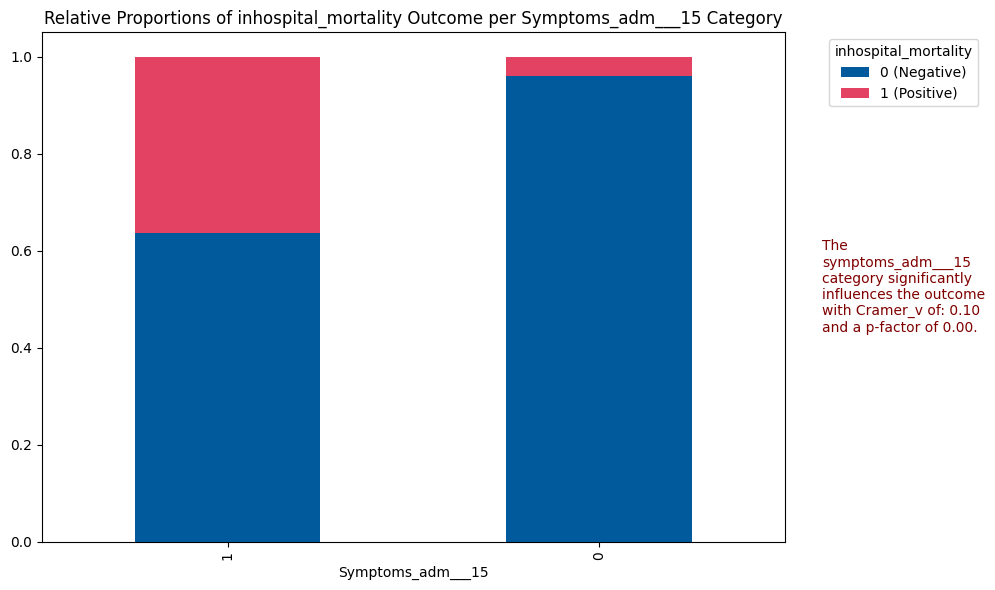

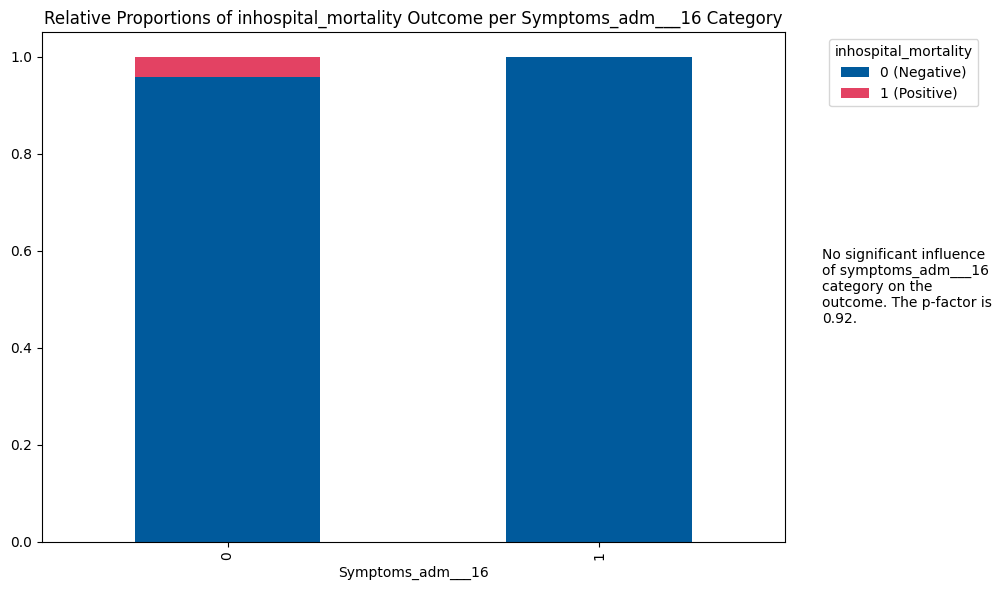

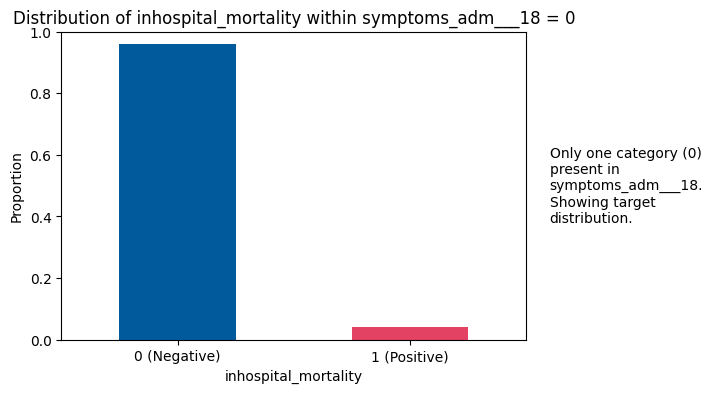

In [28]:
for col in special_features:
    try:
        categorical_analysis(col, df, target, color=['#005A9C', '#E34263'])
    except Exception as e:
        print(col)
        print(e)

In [29]:
import itertools
from tqdm.notebook import tqdm
import math

results = {}

for k in tqdm(range(1, 17)):  # Looping from K = 1 to 17
    feature_combinations = itertools.combinations(special_features, k)
    num_combinations = math.comb(len(special_features), k)
    
    combined_features = {
        "_".join(cols): sum(df[col] for col in cols)
        for cols in feature_combinations
    }
    
    for feature_name, feature_values in tqdm(combined_features.items(), total=num_combinations, leave=False):
        tmp = feature_values.copy()
        tmp.name = feature_name
        tmp = tmp.to_frame()
        tmp[target] = df[target]
        
        result = categorical_analysis(feature_name, tmp, target, 
                                      return_result_only=True)
        
        results[feature_name] = result

for k, v in results.items():
    if v and v > 0.3:
        print(k, v)


  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/136 [00:00<?, ?it/s]

  0%|          | 0/680 [00:00<?, ?it/s]

  0%|          | 0/2380 [00:00<?, ?it/s]

  0%|          | 0/6188 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/2380 [00:00<?, ?it/s]

  0%|          | 0/680 [00:00<?, ?it/s]

  0%|          | 0/136 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

In [32]:
for k, v in results.items():
    if v and v > 0.168:
        print(k, v)

symptoms_adm___1_symptoms_adm___3_symptoms_adm___6_symptoms_adm___7_symptoms_adm___13_symptoms_adm___14 0.16810248889953852
symptoms_adm___1_symptoms_adm___3_symptoms_adm___6_symptoms_adm___7_symptoms_adm___13_symptoms_adm___14_symptoms_adm___18 0.16810248889953852


In [20]:
for k, v in results.items():
    if v and v > 0.168:
        print(k, v)

symptoms_adm___1_symptoms_adm___3_symptoms_adm___6_symptoms_adm___7_symptoms_adm___13_symptoms_adm___14 0.16810248889953852
symptoms_adm___1_symptoms_adm___3_symptoms_adm___6_symptoms_adm___7_symptoms_adm___13_symptoms_adm___14_symptoms_adm___17 0.16810248889953852
symptoms_adm___1_symptoms_adm___3_symptoms_adm___6_symptoms_adm___7_symptoms_adm___13_symptoms_adm___14_symptoms_adm___18 0.16810248889953852
symptoms_adm___1_symptoms_adm___3_symptoms_adm___6_symptoms_adm___7_symptoms_adm___13_symptoms_adm___14_symptoms_adm___17_symptoms_adm___18 0.16810248889953852


In [ ]:
df['combo'] = df['symptoms_adm___1'] + df['symptoms_adm___3'] + df['symptoms_adm___6'] + df['symptoms_adm___7'] + df['symptoms_adm___13'] + df['symptoms_adm___14']

In [40]:
df.combo.value_counts()


combo
1    1354
2     601
0     106
3      76
4      10
5       1
Name: count, dtype: int64

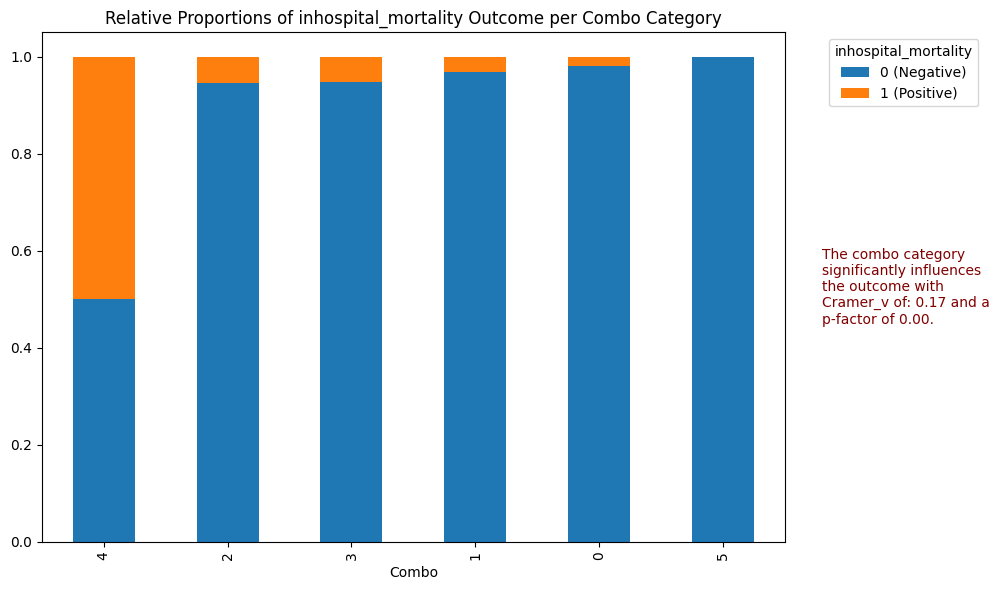

In [41]:
categorical_analysis('combo', df, target)

combo_binary
0    2137
1      11
Name: count, dtype: int64


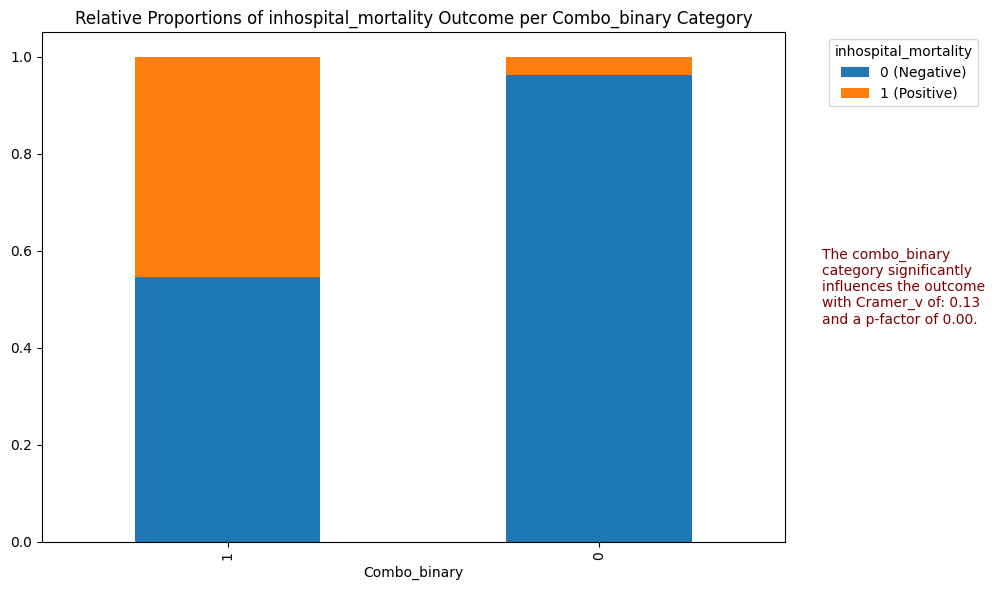

In [48]:
df['combo_binary'] = np.where(df['combo']>=4, 1, 0)
print(df.combo_binary.value_counts())
categorical_analysis('combo_binary', df, target)

In [49]:
df['combo'].dtype

dtype('int64')

In [50]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(df['combo'], df[target])
print(f"Spearman correlation: {correlation}, p-value: {p_value}")


Spearman correlation: 0.07659973446270227, p-value: 0.00038045047659891187


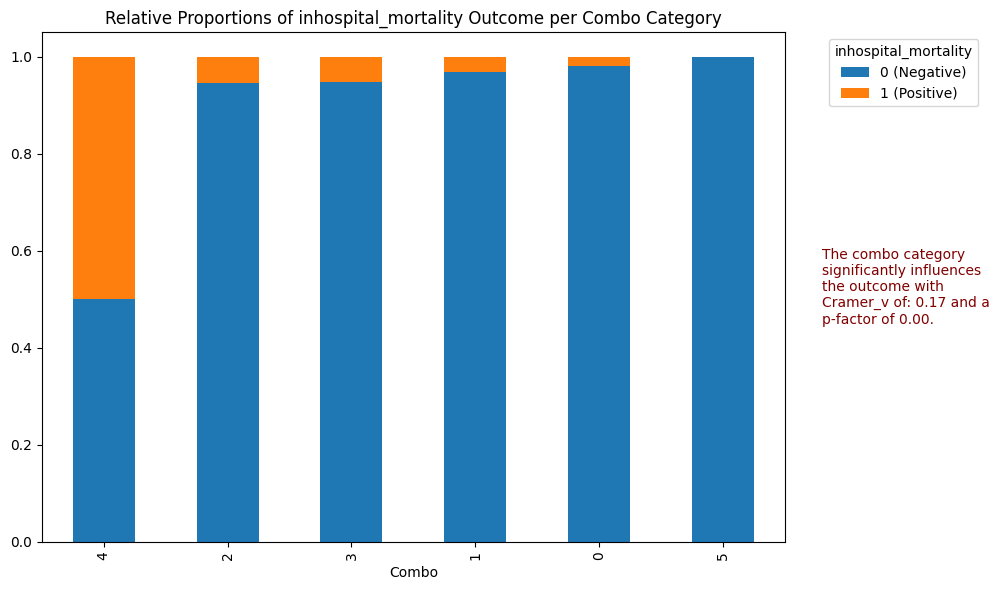

In [51]:
df['combo'] = df['symptoms_adm___1'] + df['symptoms_adm___3'] + df['symptoms_adm___6'] + df['symptoms_adm___7'] + df['symptoms_adm___13'] + df['symptoms_adm___14']
categorical_analysis('combo', df, target)

combo_binary
0    2137
1      11
Name: count, dtype: int64


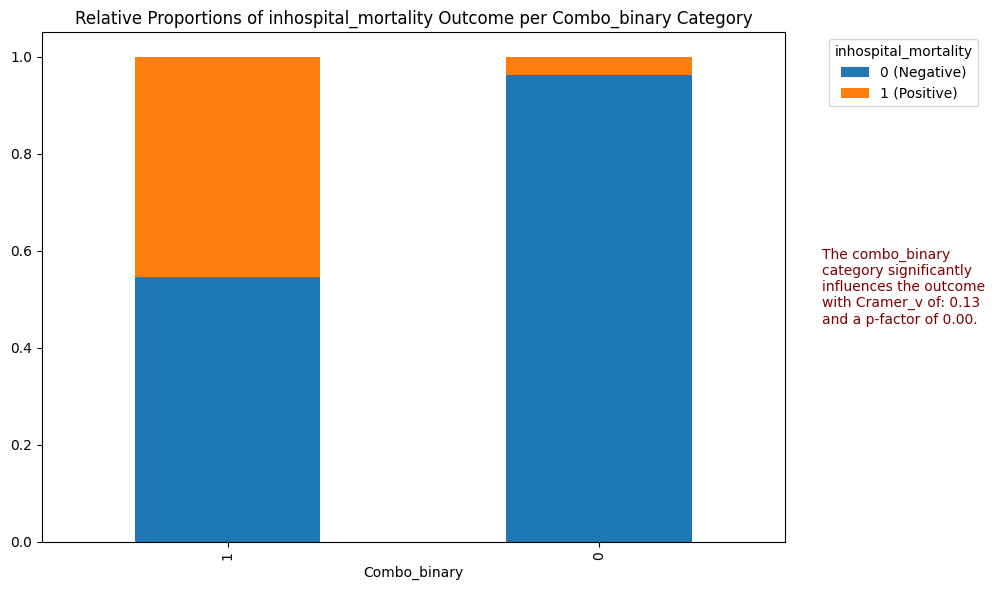

In [52]:
df['combo_binary'] = np.where(df['combo']>=4, 1, 0)
print(df.combo_binary.value_counts())
categorical_analysis('combo_binary', df, target)